<a href="https://colab.research.google.com/github/Notrealatharv/APC-PRAC-TY-S5/blob/main/sentimenter.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

!pip -q install scikit-learn pandas numpy joblib
print("Libraries installed successfully!")


Libraries installed successfully!


In [ ]:

import pandas as pd

data = {
    "text": [
        "This product is amazing and works perfectly",
        "I absolutely love this excellent service",
        "Very happy with my purchase",
        "The quality is fantastic",
        "Great experience, highly recommended",
        "The product is terrible and disappointing",
        "I hate this poor quality item",
        "Very bad service and a waste of money",
        "The product stopped working and I am unhappy",
        "Awful experience, would not recommend",
        "The package arrived today",
        "The product has two buttons",
        "I received the order this morning",
        "The box contains a charger and cable",
        "The item is available in three colors",
        "The battery lasts all day",
        "Battery life is excellent and impressive",
        "The battery drains too quickly",
        "Delivery was on time and the item is good",
        "Delivery was late and the package was damaged",
        "The phone has a six inch display",
        "The display is bright and beautiful",
        "The display is dull and difficult to read",
        "Customer support resolved my issue quickly",
        "Customer support was rude and unhelpful",
        "It arrived in a standard cardboard box",
        "The instructions are clear and easy to follow",
        "The instructions are confusing and incomplete",
        "I am satisfied with the overall performance",
        "I am disappointed with the overall performance"
    ],
    "sentiment": [
        "positive", "positive", "positive", "positive", "positive",
        "negative", "negative", "negative", "negative", "negative",
        "neutral", "neutral", "neutral", "neutral", "neutral",
        "positive", "positive", "negative", "positive", "negative",
        "neutral", "positive", "negative", "positive", "negative",
        "neutral", "positive", "negative", "positive", "negative"
    ]
}

df = pd.DataFrame(data)

print("Dataset shape:", df.shape)
print("\nClass distribution:")
print(df["sentiment"].value_counts())

df.head()


Dataset shape: (30, 2)

Class distribution:
sentiment
positive    12
negative    11
neutral      7
Name: count, dtype: int64


,text,sentiment
0,This product is amazing and works perfectly,positive
1,I absolutely love this excellent service,positive
2,Very happy with my purchase,positive
3,The quality is fantastic,positive
4,"Great experience, highly recommended",positive


In [ ]:

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score

X = df["text"]
y = df["sentiment"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

model = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True,
        ngram_range=(1, 2),
        sublinear_tf=True
    )),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

model.fit(X_train, y_train)

predictions = model.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, predictions), 3))
print("\nClassification report:")
print(classification_report(y_test, predictions, zero_division=0))


Accuracy: 0.25

Classification report:
              precision    recall  f1-score   support

    negative       0.33      0.67      0.44         3
     neutral       0.00      0.00      0.00         2
    positive       0.00      0.00      0.00         3

    accuracy                           0.25         8
   macro avg       0.11      0.22      0.15         8
weighted avg       0.12      0.25      0.17         8



In [ ]:

def predict_sentiment(text):
    sentiment = model.predict([text])[0]
    probabilities = model.predict_proba([text])[0]

    print("\nText:", text)
    print("Predicted sentiment:", sentiment.upper())
    print("Model score breakdown:")

    for label, probability in zip(
        model.classes_, probabilities
    ):
        print(f"  {label.capitalize()}: {probability:.1%}")


predict_sentiment("I love this product, it works perfectly!")
predict_sentiment("The service was awful and disappointing.")
predict_sentiment("The package arrived this morning.")



Text: I love this product, it works perfectly!
Predicted sentiment: POSITIVE
Model score breakdown:
  Negative: 29.2%
  Neutral: 31.2%
  Positive: 39.6%

Text: The service was awful and disappointing.
Predicted sentiment: NEGATIVE
Model score breakdown:
  Negative: 47.7%
  Neutral: 24.1%
  Positive: 28.2%

Text: The package arrived this morning.
Predicted sentiment: NEUTRAL
Model score breakdown:
  Negative: 22.6%
  Neutral: 55.0%
  Positive: 22.4%


In [ ]:

results = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": predictions,
    "Text": X_test.values
})

print(results.to_string(index=False))



  Actual Predicted                                          Text
negative  positive     The display is dull and difficult to read
positive  negative                     The battery lasts all day
positive  negative     Delivery was on time and the item is good
negative  negative Delivery was late and the package was damaged
positive  negative      I absolutely love this excellent service
 neutral  negative          The box contains a charger and cable
negative  negative  The product stopped working and I am unhappy
 neutral  positive         The item is available in three colors


BY USING REAL DATA SET REAL DATASET

In [ ]:

!pip -q install datasets scikit-learn pandas joblib


%pip install -q "huggingface-hub>=1.32.0,<2.0"



In [ ]:

from datasets import load_dataset

dataset = load_dataset(
    "cardiffnlp/tweet_eval",
    "sentiment"
)

train_data = dataset["train"].to_pandas()
test_data = dataset["test"].to_pandas()

label_names = ["negative", "neutral", "positive"]

train_data["sentiment"] = train_data["label"].map(
    lambda x: label_names[x]
)
test_data["sentiment"] = test_data["label"].map(
    lambda x: label_names[x]
)

print("Training rows:", len(train_data))
print("Testing rows:", len(test_data))
print(train_data[["text", "sentiment"]].head())


Training rows: 45615
Testing rows: 12284
                                                text sentiment
0  "QT @user In the original draft of the 7th boo...  positive
1  "Ben Smith / Smith (concussion) remains out of...   neutral
2  Sorry bout the stream last night I crashed out...   neutral
3  Chase Headley's RBI double in the 8th inning o...   neutral
4  @user Alciato: Bee will invest 150 million in ...  positive


In [ ]:

import pandas as pd

label_names = ["negative", "neutral", "positive"]

train_data = dataset["train"].to_pandas()
test_data = dataset["test"].to_pandas()

train_data["sentiment"] = train_data["label"].map(
    lambda x: label_names[x]
)

test_data["sentiment"] = test_data["label"].map(
    lambda x: label_names[x]
)

print("Training samples:", len(train_data))
print("Testing samples:", len(test_data))

print("\nTraining class distribution:")
print(train_data["sentiment"].value_counts())

print("\nSample reviews:")
display(train_data[["text", "sentiment"]].head(10))


Training samples: 45615
Testing samples: 12284

Training class distribution:
sentiment
neutral     20673
positive    17849
negative     7093
Name: count, dtype: int64

Sample reviews:


,text,sentiment
0,"""QT @user In the original draft of the 7th boo...",positive
1,"""Ben Smith / Smith (concussion) remains out of...",neutral
2,Sorry bout the stream last night I crashed out...,neutral
3,Chase Headley's RBI double in the 8th inning o...,neutral
4,@user Alciato: Bee will invest 150 million in ...,positive
5,@user LIT MY MUM 'Kerry the louboutins I wonde...,positive
6,"""\"""""""" SOUL TRAIN\"""""""" OCT 27 HALLOWEEN SPECIA...",positive
7,So disappointed in wwe summerslam! I want to s...,negative
8,"""This is the last Sunday w/o football .....,NF...",positive
9,@user @user CENA & AJ sitting in a tree K-I-S-...,neutral


In [ ]:
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC

# Combine word-level and char-level TF-IDF vectorizers to capture both complete words and sub-word patterns (emojis, prefixes, endings)
word_vectorizer = TfidfVectorizer(
    analyzer="word",
    ngram_range=(1, 3),
    min_df=2,
    max_df=0.8,
    sublinear_tf=True
)

char_vectorizer = TfidfVectorizer(
    analyzer="char_wb",
    ngram_range=(3, 5),
    min_df=3,
    max_df=0.8,
    sublinear_tf=True
)

model = Pipeline([
    ("features", FeatureUnion([
        ("word", word_vectorizer),
        ("char", char_vectorizer)
    ])),
    ("classifier", LinearSVC(
        C=0.2,
        class_weight="balanced",
        random_state=42,
        max_iter=3000
    ))
])

print("Training maximum accuracy ensemble TF-IDF model...")

model.fit(
    train_data["text"],
    train_data["sentiment"]
)

print("Training completed successfully!")

Training maximum accuracy ensemble TF-IDF model...
Training completed successfully!


Test Accuracy: 62.41%

Classification Report:

              precision    recall  f1-score   support

    negative       0.63      0.61      0.62      3972
     neutral       0.66      0.62      0.64      5937
    positive       0.56      0.66      0.60      2375

    accuracy                           0.62     12284
   macro avg       0.61      0.63      0.62     12284
weighted avg       0.63      0.62      0.62     12284



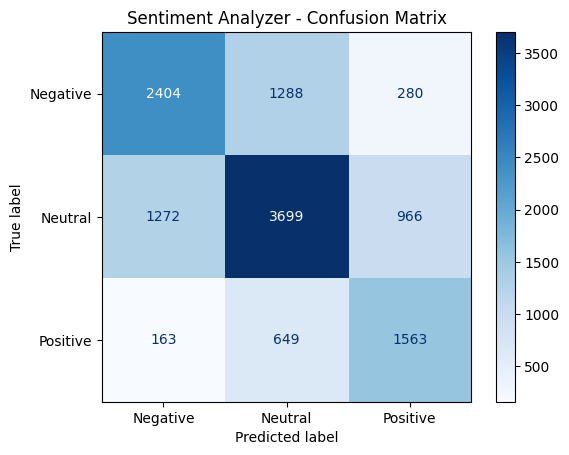

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

X_test = test_data["text"]
y_test = test_data["sentiment"]

predictions = model.predict(X_test)

accuracy = accuracy_score(y_test, predictions)

print(f"Test Accuracy: {accuracy:.2%}")
print("\nClassification Report:\n")

print(classification_report(
    y_test,
    predictions,
    labels=["negative", "neutral", "positive"],
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    predictions,
    labels=["negative", "neutral", "positive"],
    display_labels=["Negative", "Neutral", "Positive"],
    cmap="Blues"
)

plt.title("Sentiment Analyzer - Confusion Matrix")
plt.show()

In [ ]:
def predict_sentiment(text):
    prediction = model.predict([text])[0]
    # LinearSVC has decision_function instead of predict_proba
    scores = model.decision_function([text])[0]

    print("\nText:", text)
    print("Predicted sentiment:", prediction.upper())
    print("\nClass scores (decision values):")

    for label, score in zip(model.classes_, scores):
        print(f"{label.capitalize()}: {score:.4f}")


predict_sentiment("I absolutely love this product!")
predict_sentiment("This is the worst service I have ever experienced.")
predict_sentiment("The package arrived this morning.")
predict_sentiment("The product is good but the battery is disappointing.")


Text: I absolutely love this product!
Predicted sentiment: POSITIVE

Class scores (decision values):
Negative: -0.9161
Neutral: -1.5907
Positive: 1.2352

Text: This is the worst service I have ever experienced.
Predicted sentiment: NEGATIVE

Class scores (decision values):
Negative: 1.3404
Neutral: -1.1421
Positive: -1.1554

Text: The package arrived this morning.
Predicted sentiment: NEUTRAL

Class scores (decision values):
Negative: -0.3649
Neutral: -0.0919
Positive: -0.4604

Text: The product is good but the battery is disappointing.
Predicted sentiment: NEGATIVE

Class scores (decision values):
Negative: 0.4113
Neutral: -1.2088
Positive: -0.0422


In [ ]:

import joblib

joblib.dump(model, "sentiment_model.joblib")

print("Model saved successfully!")


Model saved successfully!


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, clear_output
import ipywidgets as widgets

text_input = widgets.Textarea(
    value="I absolutely love this product!",
    placeholder="Enter a review, comment, or sentence...",
    description="Text:",
    layout=widgets.Layout(width="100%", height="120px")
)

analyze_button = widgets.Button(
    description="Analyze Sentiment",
    button_style="success",
    icon="search"
)

output = widgets.Output()

def analyze_text(button):
    with output:
        clear_output(wait=True)

        text = text_input.value.strip()

        if not text:
            print("Please enter some text.")
            return

        prediction = model.predict([text])[0]
        # LinearSVC has decision_function instead of predict_proba
        scores_array = model.decision_function([text])[0]

        print("SENTIMENT ANALYSIS")
        print("=" * 40)
        print("Input:", text)
        print("Predicted sentiment:", prediction.upper())
        print("\nClass scores (decision values):")

        scores = {}
        for label, score in zip(model.classes_, scores_array):
            scores[label.capitalize()] = score
            print(f"{label.capitalize():10}: {score:.4f}")

        plt.figure(figsize=(7, 3))
        plt.bar(scores.keys(), scores.values(), color=['red' if x < 0 else 'green' for x in scores.values()])
        plt.ylabel("Decision Score")
        plt.title("Sentiment Decision Scores (Positive values favor the class)")
        plt.axhline(0, color='black', linewidth=0.8, linestyle='--')
        plt.show()

analyze_button.on_click(analyze_text)

display(text_input, analyze_button, output)

Textarea(value='I absolutely love this product!', description='Text:', layout=Layout(height='120px', width='10…

Button(button_style='success', description='Analyze Sentiment', icon='search', style=ButtonStyle())

Output()